# 01 - Exploratory Data Analysis

Goal: understand the data before modeling. Three questions:

1. How imbalanced is the target?
2. Which columns have missing values?
3. Are there impossible or extreme values?

Every cleaning decision found here is written down with its reason.

## Setup

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sys.path.append("..")  # make the project's src/ folder importable
from src.plot_style import NU_INK, NU_PURPLE, set_plot_style

set_plot_style()

DATA_DIR = Path("../data/raw")

# Original Kaggle names are long and cryptic; meanings come from Data Dictionary.xls.
COLUMN_NAMES = {
    "SeriousDlqin2yrs": "defaulted",  # target: 90+ days past due within the next 2 years
    "RevolvingUtilizationOfUnsecuredLines": "credit_utilization",  # card/credit line balance / limits
    "age": "age",
    "NumberOfTime30-59DaysPastDueNotWorse": "late_30_59_days",  # times 30-59 days late, last 2 years
    "NumberOfTime60-89DaysPastDueNotWorse": "late_60_89_days",  # times 60-89 days late, last 2 years
    "NumberOfTimes90DaysLate": "late_90_plus_days",  # times 90+ days late
    "DebtRatio": "debt_ratio",  # monthly debt payments and living costs / monthly gross income
    "MonthlyIncome": "monthly_income",
    "NumberOfOpenCreditLinesAndLoans": "open_credit_lines_loans",
    "NumberRealEstateLoansOrLines": "real_estate_loans",
    "NumberOfDependents": "dependents",  # excluding the borrower
}
TARGET = "defaulted"

# The first CSV column is an unnamed row id, so use it as the index.
df = pd.read_csv(DATA_DIR / "cs-training.csv", index_col=0).rename(columns=COLUMN_NAMES)
df.shape

(150000, 11)

In [2]:
df.head()

,defaulted,credit_utilization,age,late_30_59_days,debt_ratio,monthly_income,open_credit_lines_loans,late_90_plus_days,real_estate_loans,late_60_89_days,dependents
1,1,0.766127,45,2,0.802982,9120.0,13,0,6,0,2.0
2,0,0.957151,40,0,0.121876,2600.0,4,0,0,0,1.0
3,0,0.658180,38,1,0.085113,3042.0,2,1,0,0,0.0
4,0,0.233810,30,0,0.036050,3300.0,5,0,0,0,0.0
5,0,0.907239,49,1,0.024926,63588.0,7,0,1,0,0.0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150000 entries, 1 to 150000
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   defaulted                150000 non-null  int64  
 1   credit_utilization       150000 non-null  float64
 2   age                      150000 non-null  int64  
 3   late_30_59_days          150000 non-null  int64  
 4   debt_ratio               150000 non-null  float64
 5   monthly_income           120269 non-null  float64
 6   open_credit_lines_loans  150000 non-null  int64  
 7   late_90_plus_days        150000 non-null  int64  
 8   real_estate_loans        150000 non-null  int64  
 9   late_60_89_days          150000 non-null  int64  
 10  dependents               146076 non-null  float64
dtypes: float64(4), int64(7)
memory usage: 12.6 MB


## 1. Target imbalance

What share of borrowers have `defaulted = 1`?


In [4]:
display(df[TARGET].value_counts())
display(df[TARGET].value_counts(normalize=True))

defaulted
0    139974
1     10026
Name: count, dtype: int64

defaulted
0    0.93316
1    0.06684
Name: proportion, dtype: float64

**Takeaway:** The data is imbalanced: 93.3% non-default and 6.7% default (10,026 of 150,000 borrowers).

- **Accuracy fails here.** The trivial baseline that predicts "nobody defaults" gets 93% accuracy, but recall = 0% (it never catches a default) and precision is undefined (0/0, it flags nobody).
- **We use AUC to compare models.** It does not depend on a threshold, and it measures how well the model ranks defaulters above non-defaulters. The trivial baseline gets only 0.5 (a coin flip), so AUC is not fooled the way accuracy is.
- **Consequences for later:** use stratified splits and stratified CV so every split keeps the 6.7% default rate, and set the decision threshold from the cost of each error (missed defaulter vs. rejected good customer), not the default 0.5.

## 2. Missing values

Which columns have missing values, and what share of rows?

*Hint:* `isna()` returns True/False; the mean of booleans is a proportion.

In [5]:
# missing data
missing_data = df.isna().mean()

display(missing_data[missing_data > 0].sort_values(ascending=False).round(4)*100)

monthly_income    19.82
dependents         2.62
dtype: float64

**Takeaway:** Missing values are concentrated in two columns: `monthly_income` (19.8%) and `dependents` (2.6%).

`monthly_income` is missing for about one fifth of the rows, so dropping them would throw away a lot of data and could distort the predictions.

On the other hand, `dependents` is missing for only 2.6% of the rows.

In [6]:
# Are both columns missing in the same rows?

both_missing = (df['monthly_income'].isna() & df['dependents'].isna()).sum()

display(both_missing)

np.int64(3924)

**Takeaway:** Every row missing `dependents` is also missing `monthly_income` (3,924 of 3,924). There is no row where only `dependents` is missing.

So the rows missing `dependents` are a **subset** of the rows missing `monthly_income`, which suggests a shared cause (e.g. a skipped section of the application).

In [7]:
# debt_ratio = monthly debt / monthly income, so compare it with income missing vs. present.
missing_income = df['monthly_income'].isna()

display(df.loc[missing_income,'debt_ratio'].describe())
display(df.loc[~missing_income, "debt_ratio"].describe())

count     29731.000000
mean       1673.396556
std        4248.372895
min           0.000000
25%         123.000000
50%        1159.000000
75%        2382.000000
max      329664.000000
Name: debt_ratio, dtype: float64

count    120269.000000
mean         26.598777
std         424.446457
min           0.000000
25%           0.143388
50%           0.296023
75%           0.482559
max       61106.500000
Name: debt_ratio, dtype: float64

**Takeaway: `debt_ratio` changes meaning when income is missing**

| Group | Median `debt_ratio` |
|---|---|
| Income present | 0.30 (a ratio: debt is 30% of income) |
| Income missing | 1,159 (looks like an amount of money) |

**Hypothesis:** `debt_ratio` = monthly debt ÷ monthly income. When income is missing there is nothing to divide by, so the stored value looks like the **monthly debt amount itself**. The data dictionary does not document this, so it is a hypothesis supported by the data, not a confirmed fact.

**Why it matters:** one column with two meanings (like mixing two units) means the model cannot tell which is which:
1. **Logistic regression** learns a single coefficient for `debt_ratio`, and the huge values from the missing-income group dominate it.
2. **Tree models** learn that `debt_ratio > 10` almost always means "income missing", so the feature silently becomes a missing-income detector and its interpretation is wrong.

**Decision:** inside the modeling `Pipeline`:
- set `debt_ratio` to missing when `monthly_income` is missing,
- impute both columns (fitted on training data only),
- add an `income_missing` flag so the model keeps the information that income was not reported.

**To verify after the train/holdout split:** compare the default rate for `income_missing = 1` vs `0` on the training set. If they differ, the flag carries real signal.

## 3. Impossible or extreme values

Look at the summary statistics. Check `age`, the three `late_*` columns, `debt_ratio` and `credit_utilization`.

*Hint:* `describe()` shows min/max; add `percentiles=[...]` to see the tails (e.g. 0.99).

In [8]:
# your code here

# Age makes sense , no negative values , and the max of 109 years is possible and its average is 52.2 , ok
df['age'].describe(percentiles=[0.01,0.5,0.99])

count    150000.000000
mean         52.295207
std          14.771866
min           0.000000
1%           24.000000
50%          52.000000
99%          87.000000
max         109.000000
Name: age, dtype: float64

In [9]:
# Credit utilization = Balance / credit limit
df['credit_utilization'].describe(percentiles = [0.01,0.5,0.999])
# Looks like there is something weird on the max , how we can have such a huge number ,we would need a low credit limit or high balance

# The max is way higher than the other values : I will use a log scale to spread the values evenly


count    150000.000000
mean          6.048438
std         249.755371
min           0.000000
1%            0.000000
50%           0.154181
99.9%      1571.006000
max       50708.000000
Name: credit_utilization, dtype: float64

In [10]:
# How many zeros ?
zero_credit =df['credit_utilization'] == 0

zero_credit.sum()

np.int64(10878)

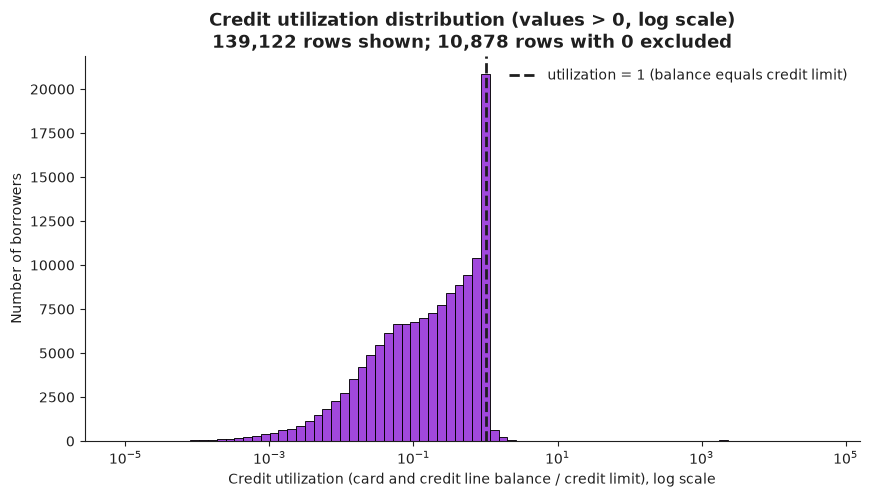

In [11]:
# Plotting credit utilization to see its distribution.
# Log scale spreads values from 0.00001 to 50,000; log cannot show 0, so zeros are excluded.

log_filter = df['credit_utilization'] > 0
log_credit = df.loc[log_filter, 'credit_utilization']

fig, ax = plt.subplots()
sns.histplot(log_credit, log_scale=True, bins=80, color=NU_PURPLE, ax=ax)
ax.axvline(x=1.0, color=NU_INK, linestyle="--", linewidth=2,
           label="utilization = 1 (balance equals credit limit)")

ax.set_title(f"Credit utilization distribution (values > 0, log scale)\n"
             f"{len(log_credit):,} rows shown; {(~log_filter).sum():,} rows with 0 excluded")
ax.set_xlabel("Credit utilization (card and credit line balance / credit limit), log scale")
ax.set_ylabel("Number of borrowers")
ax.legend(frameon=False)
plt.show()

In [32]:
(df['credit_utilization']==1).sum()

np.int64(17)

In [23]:
# In the graph it is 20 000 , but it appears only 11062
between_99_1= (df['credit_utilization'] <=1) & (df['credit_utilization']>=0.99)
between_99_1.sum()

np.int64(11062)

In [30]:
df.loc[between_99_1,'credit_utilization'].value_counts()


credit_utilization
1.000000    10256
1.000000       17
0.994012        5
0.992016        4
0.996400        4
            ...  
0.996337        1
0.993470        1
0.996939        1
0.998262        1
0.994728        1
Name: count, Length: 726, dtype: int64

### 10256 numbers with credit_utilization = 0.9999999

In [35]:
# Values > 1
above_1 = df['credit_utilization']>1
above_1.sum()

# The balance is bigger than credit limit

# Someone over limit could be defaulting. What is more real are people up to 2.
# Values 10+ are very unlikely , means owning 10 times the limit , and banks block the account way before.

np.int64(3321)

In [36]:
(df['credit_utilization']>10).sum()


np.int64(241)

In [64]:
above = df.loc[above_1,'credit_utilization'].describe(percentiles =[0.01,0.5,0.99,0.999])
above

count     3321.000000
mean       259.773362
std       1659.034074
min          1.000059
1%           1.000929
50%          1.074633
99%       6723.000000
99.9%    21524.480000
max      50708.000000
Name: credit_utilization, dtype: float64

### The mean is much bigger than the median . it means many big values are dragging the mean . 

<Axes: xlabel='credit_utilization', ylabel='Count'>

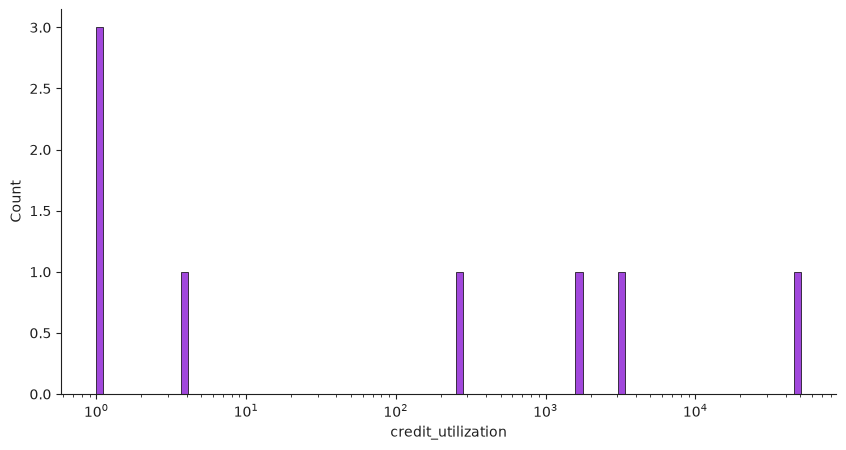

In [63]:
sns.histplot(above,log_scale=True , bins=100)

*Takeway* : In credit_utilization there are many extreme signals .

Looking into the data between 0.99 and 1 , we see the big majority in 0.999999 (with many decimals equal). it looks like a label and not their measure. This group could distort the parameter

**Takeaway:** _list each suspicious value, why it is suspicious, and what you would do._